# 03 - Modeling Results
All numbers below are read from files written by `python -m src.train`. Nothing is hard-coded.

In [1]:
import sys
sys.path.insert(0, "..")
import warnings; warnings.filterwarnings("ignore")
import numpy as np, pandas as pd
import matplotlib.pyplot as plt, seaborn as sns
from src import config
sns.set_theme(style="whitegrid")
pd.set_option("display.width", 200)
def save(name):
    plt.tight_layout(); plt.savefig(config.FIGURES_DIR / name, dpi=110); plt.show()
import json
from IPython.display import Image, display
R = config.REPORTS_DIR
settings = json.loads(config.SETTINGS_PATH.read_text())
def show(name, width=700): display(Image(str(config.FIGURES_DIR / name), width=width))

## Baseline and model comparison (5-fold CV on training data)

In [2]:
print(open(R / 'baseline_logreg.txt').read()[:120])
pd.read_csv(R / 'model_results.csv')

{
  "accuracy": 0.8423,
  "balanced_accuracy": 0.8163,
  "precision": 0.5786,
  "recall": 0.7731,
  "f1": 0.6619,
  "roc


,model,roc_auc,pr_auc,precision,recall,f1,balanced_accuracy,brier,fit_seconds
0,Logistic Regression,0.9121,0.7914,0.5917,0.8149,0.6855,0.8374,0.1102,0.0461
1,Decision Tree,0.8816,0.7200,0.6083,0.7834,0.6843,0.8287,0.1163,0.0553
2,Random Forest,0.9481,0.8366,0.7816,0.7297,0.7546,0.8395,0.0711,2.0198
3,Gradient Boosting,0.9414,0.8509,0.8428,0.6814,0.7532,0.8249,0.0675,1.4288
4,XGBoost,0.9492,0.8742,0.7554,0.8181,0.7855,0.8760,0.0711,0.2715


Logistic regression is the standard credit-scoring baseline: fast, stable, and its coefficients are easy to explain to regulators and business teams. Tree ensembles beat it clearly on ROC-AUC and PR-AUC because default risk here depends on interactions and thresholds (for example, missing debt-to-income combined with delinquencies).

## Class imbalance strategies

In [3]:
pd.read_csv(R / 'imbalance_results.csv')

,model,strategy,roc_auc,pr_auc,precision,recall,f1,balanced_accuracy,brier,fit_seconds
0,Logistic Regression,none,0.9119,0.7924,0.7991,0.6161,0.6952,0.7887,0.0805,0.0431
1,Logistic Regression,class_weight,0.9121,0.7914,0.5917,0.8149,0.6855,0.8374,0.1102,0.0459
2,Logistic Regression,smote,0.9102,0.7893,0.6102,0.8044,0.6939,0.8381,0.1079,0.0627
3,Random Forest,none,0.9507,0.8572,0.8460,0.6950,0.7625,0.8317,0.0671,1.4949
4,Random Forest,class_weight,0.9479,0.8376,0.7777,0.7234,0.7493,0.8359,0.0711,1.3057
5,Random Forest,smote,0.9500,0.8402,0.8136,0.7182,0.7626,0.8385,0.0685,2.3356


For Random Forest, no rebalancing gave the best PR-AUC, and SMOTE did not improve it. For logistic regression, class weights and SMOTE shift recall up and precision down but leave ROC-AUC and PR-AUC almost unchanged, so they mostly move the operating point. Threshold selection and calibration handle that more directly.

## Hyperparameter tuning (RandomizedSearchCV, scoring PR-AUC)

In [4]:
pd.read_csv(R / 'tuned_results.csv')

,model,cv_pr_auc,best_params,test_accuracy,test_balanced_accuracy,test_precision,test_recall,test_f1,test_roc_auc,test_pr_auc,test_brier
0,Logistic Regression,0.7914,"{""C"": 1}",0.8423,0.8163,0.5786,0.7731,0.6619,0.9074,0.7866,0.1133
1,Random Forest,0.8404,"{""n_estimators"": 200, ""min_samples_leaf"": 1, ""...",0.8943,0.8094,0.7718,0.6681,0.7162,0.9501,0.8325,0.0719
2,Gradient Boosting,0.8923,"{""subsample"": 0.8, ""n_estimators"": 300, ""min_s...",0.9069,0.8094,0.8508,0.6471,0.7351,0.9558,0.8784,0.0643
3,XGBoost,0.9024,"{""subsample"": 1.0, ""n_estimators"": 300, ""min_c...",0.9186,0.8514,0.8341,0.7395,0.7840,0.9559,0.8914,0.0591


## Calibration

In [5]:
pd.read_csv(R / 'calibration_results.csv')

,method,cv_brier,cv_log_loss,test_brier,test_log_loss
0,raw,0.0543,0.1935,0.0591,0.2090
1,sigmoid,0.0526,0.1807,0.0571,0.1945
2,isotonic,0.0531,0.1851,0.0566,0.2006


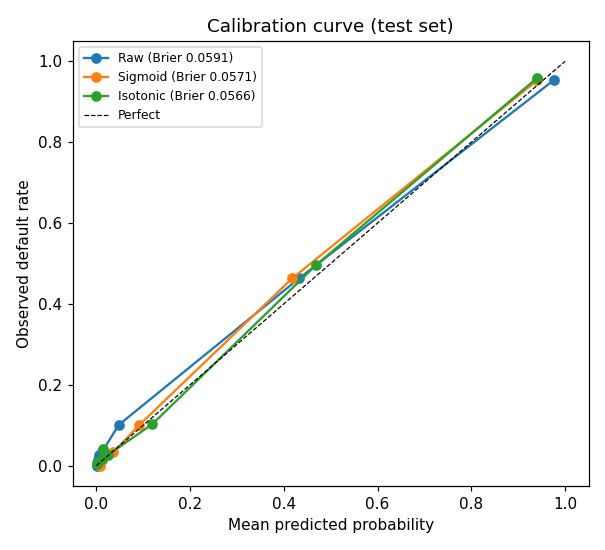

In [6]:
show('calibration_curve.png', 480)

Sigmoid scaling had the lowest cross-validated Brier score and was selected. The XGBoost model was trained with a positive-class weight, which inflates raw probabilities, so calibration matters here.

## Threshold analysis (cross-validated predictions on training data)

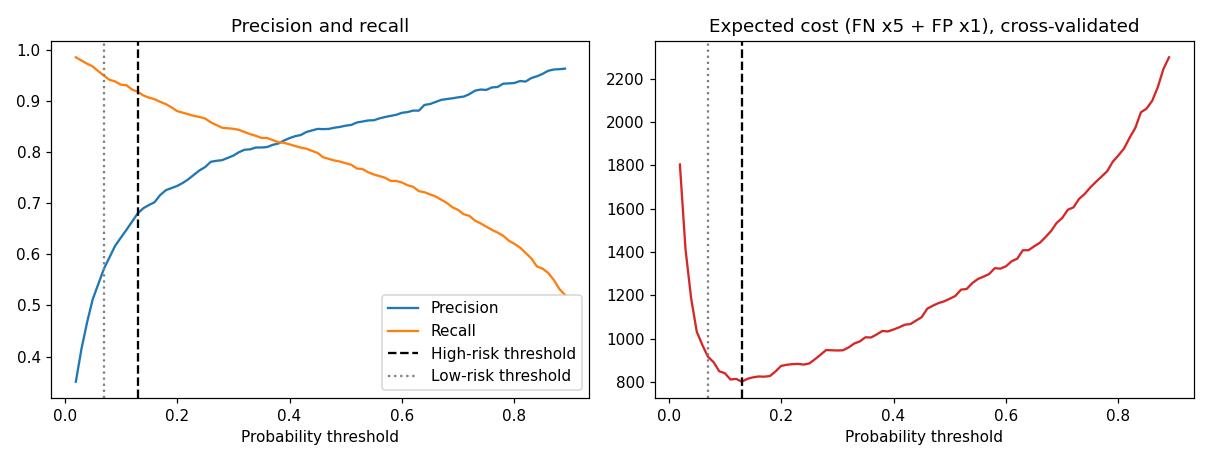

,threshold,precision,recall,false_positives,false_negatives,high_risk_count,high_risk_share,expected_cost
0,0.05,0.512,0.967,877,31,1797,0.377,1032.0
1,0.10,0.632,0.932,515,65,1401,0.294,840.0
2,0.15,0.696,0.906,376,89,1238,0.260,821.0
3,0.20,0.734,0.880,304,114,1141,0.239,874.0
4,0.25,0.771,0.865,245,128,1068,0.224,885.0
5,0.30,0.793,0.845,210,147,1014,0.213,945.0
6,0.35,0.809,0.828,186,164,973,0.204,1006.0
7,0.40,0.827,0.815,162,176,937,0.196,1042.0
8,0.45,0.845,0.798,139,192,898,0.188,1099.0
9,0.50,0.852,0.778,129,211,869,0.182,1184.0


In [7]:
show('threshold_analysis.png', 850)
pd.read_csv(R / 'threshold_analysis.csv').round(3)

In [8]:
print(settings['thresholds'], 'FN:FP cost ratio =', settings['cost_ratio_fn_to_fp'])

{'low_risk': 0.07, 'high_risk': 0.13} FN:FP cost ratio = 5.0


Business assumption: approving a loan that defaults costs about five times as much as rejecting a good applicant. The high-risk threshold is the probability that minimises this expected cost. The low-risk threshold is set so that only about 5% of real defaulters score below it.

## Final test-set performance

In [9]:
pd.DataFrame({'baseline LR @0.5': settings['baseline_test_metrics'], 'final @0.5': settings['test_metrics_at_0.5'], 'final @chosen threshold': settings['test_metrics']}).round(3)

,baseline LR @0.5,final @0.5,final @chosen threshold
accuracy,0.842,0.918,0.895
balanced_accuracy,0.816,0.841,0.898
precision,0.579,0.850,0.678
recall,0.773,0.714,0.903
f1,0.662,0.776,0.775
roc_auc,0.907,0.956,0.956
pr_auc,0.787,0.891,0.891
brier,0.113,0.057,0.057


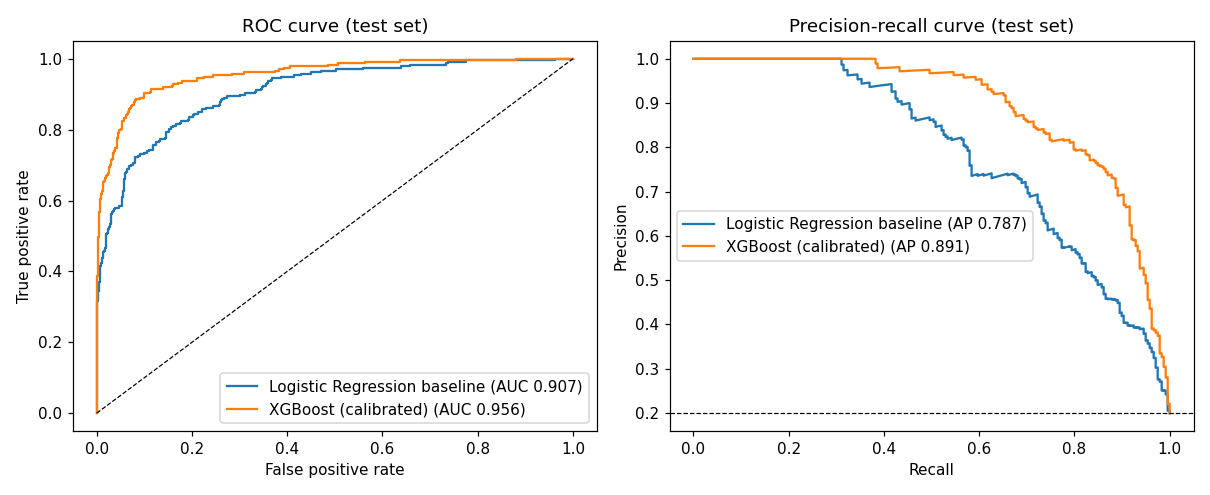

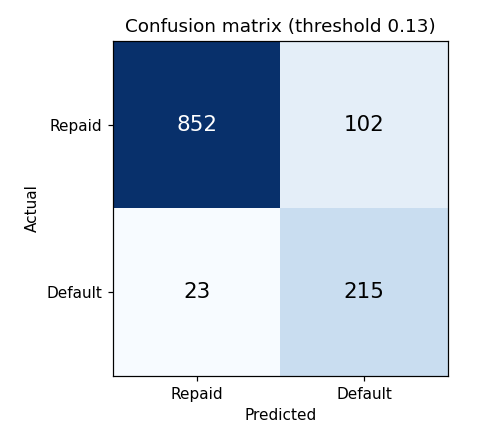

              precision    recall  f1-score   support

      Repaid       0.97      0.89      0.93       954
     Default       0.68      0.90      0.77       238

    accuracy                           0.90      1192
   macro avg       0.83      0.90      0.85      1192
weighted avg       0.91      0.90      0.90      1192

Confusion matrix [[TN, FP], [FN, TP]]:
[[852 102]
 [ 23 215]]


In [10]:
show('roc_pr_curves.png', 850); show('confusion_matrix.png', 380)
print(open(R / 'final_classification_report.txt').read())

## Explainability

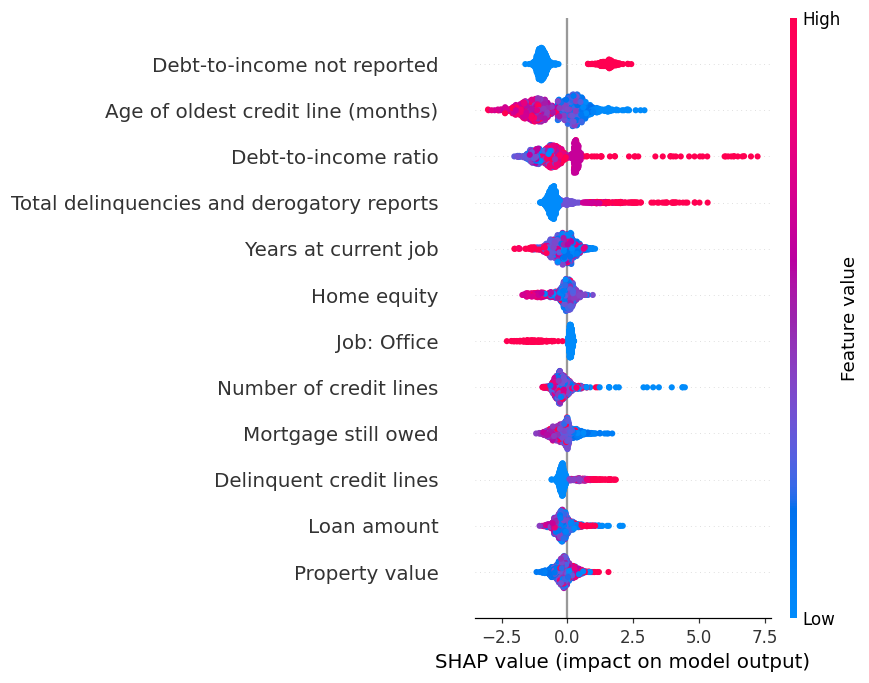

In [11]:
show('shap_summary.png', 650)

In [12]:
pd.read_csv(R / 'permutation_importance.csv').head(8)

,feature,importance,std
0,DEBTINC,0.1669,0.0129
1,DELINQ,0.1133,0.0122
2,VALUE,0.0928,0.0110
3,CLAGE,0.0719,0.0046
4,DEROG,0.0577,0.0111
5,MORTDUE,0.0563,0.0072
6,LOAN,0.0526,0.0074
7,CLNO,0.0454,0.0053


caught_default | probability 0.9998 | High Risk
  raises: [('Total delinquencies and derogatory reports', '7'), ('Property value not reported', 'yes'), ('Delinquent credit lines', '5'), ('Debt-to-income not reported', 'yes')]
  lowers: [('Loan reason: DebtCon', 'yes'), ('Recent credit inquiries', '1'), ('Total debt against property value', 'not available'), ('Inquiries per credit line', '0.06')]
missed_default | probability 0.0042 | Low Risk
  raises: [('Job: Office', 'yes'), ('Derogatory reports not reported', 'no'), ('Job: Missing', 'yes'), ('Delinquencies not reported', 'no')]
  lowers: [('Age of oldest credit line (months)', '328.51'), ('Debt-to-income ratio', '40.05'), ('Debt-to-income not reported', 'no'), ('Mortgage still owed', '129,355')]
safe_applicant | probability 0.0009 | Low Risk
  raises: [('Inquiries not reported', 'yes'), ('Loan reason: DebtCon', 'yes'), ('Job: Missing', 'yes'), ('Loan-to-value ratio', '0.22')]
  lowers: [('Derogatory reports not reported', 'yes'), ('J

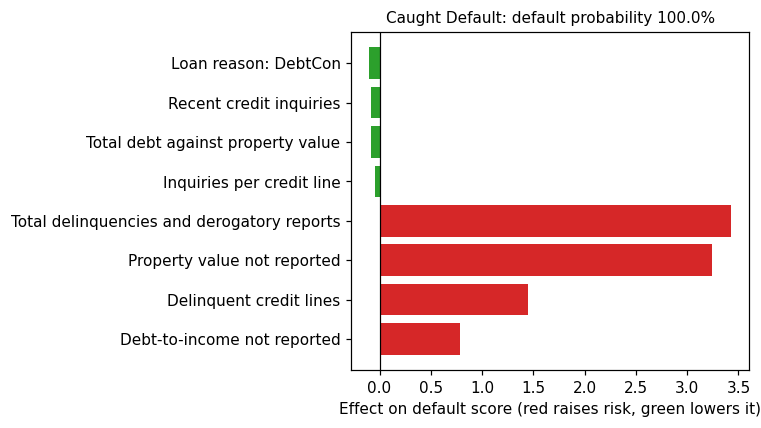

In [13]:
examples = json.loads((R / 'example_explanations.json').read_text())
for name, e in examples.items():
    print(name, '| probability', e['probability'], '|', e['risk'])
    print('  raises:', [(i['factor'], i['value']) for i in e['increase']])
    print('  lowers:', [(i['factor'], i['value']) for i in e['decrease']])
show('applicant_caught_default.png', 600)

## Error analysis

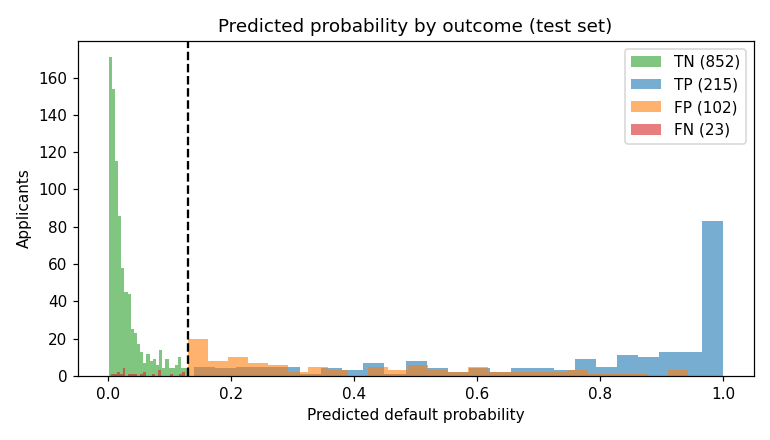

,outcome,count,share_DEBTINC_missing,probability,LOAN,VALUE,DEBTINC,DELINQ,DEROG,CLAGE,NINQ
0,FN,23,0.43,0.05,17000.0,105300.0,34.14,0.0,0.0,141.02,0.5
1,FP,102,0.60,0.30,15000.0,80284.5,36.91,0.0,0.0,131.72,1.0
2,TN,852,0.04,0.02,17400.0,93548.0,34.27,0.0,0.0,183.65,0.0
3,TP,215,0.72,0.90,15000.0,82649.0,39.15,0.0,0.0,140.93,1.0


In [14]:
show('error_probabilities.png', 600)
pd.read_csv(R / 'error_summary.csv')

In [15]:
err = pd.read_csv(R / 'test_predictions.csv', index_col=0)
print('False negatives (missed defaulters), lowest-confidence look:')
err[err.outcome == 'FN'].sort_values('probability').head(6)[['LOAN', 'VALUE', 'JOB', 'DEBTINC', 'DELINQ', 'DEROG', 'CLAGE', 'probability']]

False negatives (missed defaulters), lowest-confidence look:


,LOAN,VALUE,JOB,DEBTINC,DELINQ,DEROG,CLAGE,probability
4457,23200,171709.0,ProfExe,40.048440,0.0,0.0,328.514121,0.004247
910,9000,68994.0,Office,28.454713,1.0,0.0,137.784004,0.011942
1841,12300,84250.0,ProfExe,40.222283,NaN,NaN,NaN,0.015386
4051,21200,106273.0,ProfExe,18.114896,1.0,0.0,97.231123,0.017973
2530,15000,207562.0,ProfExe,NaN,0.0,0.0,247.584249,0.018934
5530,34600,224716.0,Mgr,32.710205,0.0,0.0,182.068461,0.024472


In [16]:
print('False positive rate by whether DEBTINC was reported and default rate in that group:')
err.groupby('DEBTINC_missing').apply(lambda g: pd.Series({'n': len(g), 'default_rate': g.actual.mean(), 'flagged_rate': g.predicted.mean(), 'false_positives': (g.outcome == 'FP').sum()})).round(3)

False positive rate by whether DEBTINC was reported and default rate in that group:


,n,default_rate,flagged_rate,false_positives
DEBTINC_missing,,,,
False,930.0,0.080,0.110,41.0
True,262.0,0.626,0.821,61.0


## Fairness and responsible ML checks

In [17]:
pd.read_csv(R / 'fairness_results.csv')

,column,group,n,actual_default_rate,flagged_high_risk_rate,recall,false_positive_rate,small_group
0,JOB,Mgr,161,0.248,0.292,0.875,0.099,False
1,JOB,Missing,49,0.122,0.102,0.667,0.023,True
2,JOB,Office,201,0.159,0.214,0.906,0.083,False
3,JOB,Other,451,0.213,0.313,0.948,0.141,False
4,JOB,ProfExe,270,0.167,0.215,0.889,0.080,False
5,JOB,Sales,17,0.294,0.235,0.400,0.167,True
6,JOB,Self,43,0.326,0.442,1.000,0.172,True
7,REASON,DebtCon,800,0.189,0.244,0.868,0.099,False
8,REASON,HomeImp,335,0.221,0.319,0.986,0.130,False
9,REASON,Missing,57,0.228,0.263,0.846,0.091,False


The dataset has no protected attributes such as race, gender or age. `JOB` is the closest sensitive proxy because occupation can correlate with protected characteristics. Groups with fewer than 50 test applicants (flagged `small_group`) give unstable estimates. The model flags a much higher share of applicants whose `DEBTINC` is missing, and many of those are actually good borrowers (high false positive rate). This is a responsible-ML concern: someone may be penalised for missing data rather than for their behaviour. This is an educational project, not a compliant lending system.